# Coin-Toss Patterns: How Long Until It Shows Up?

Toss a fair coin until a pattern such as `HT` or `TTTH` appears. How many tosses does it take on average, and how
are the waiting times spread out? Every pattern of length k is equally likely in any k given tosses, yet the
mean waiting time is not the same for all of them: `HT` takes 4 tosses on average while `HH` takes 6.

Two ways in:
- **simulation**: toss until the pattern appears, many times over
- **counting**: the number of length-n sequences that never contain the pattern gives P(waiting time > n)
  exactly, and from that the whole distribution and its mean

Rewritten in 2026 from Python 2 scripts of April 2008.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # project root, so coin_toss_patterns imports without installing
from coin_toss_patterns import patterns

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True})

## Mean tosses for every pattern of length 1 to 4

20,000 simulated runs per pattern, next to the exact mean from Conway's formula: add 2^j for every j where the
first j tosses of the pattern equal its last j tosses. In a long run every pattern of length k turns up
once every 2^k tosses on average, but a pattern that overlaps itself (`HH`, `HTH`) turns up in clusters, so the
gaps between clusters, and the wait for the first one, are longer.

In [2]:
rows = []
for k in range(1, 5):
    for p in patterns.all_sequences(k):
        waits = patterns.simulate_waiting_times(p, 20_000, rng=k)
        rows.append({"length": k, "pattern": p, "simulated mean": waits.mean(),
                     "exact mean": patterns.expected_tosses(p)})
means = pd.DataFrame(rows).set_index("pattern")
means.round(2)

,length,simulated mean,exact mean
pattern,,,
H,1,1.98,2
T,1,2.01,2
HH,2,5.91,6
HT,2,4.01,4
TH,2,4.00,4
TT,2,6.06,6
HHH,3,14.07,14
HHT,3,7.97,8
HTH,3,9.89,10


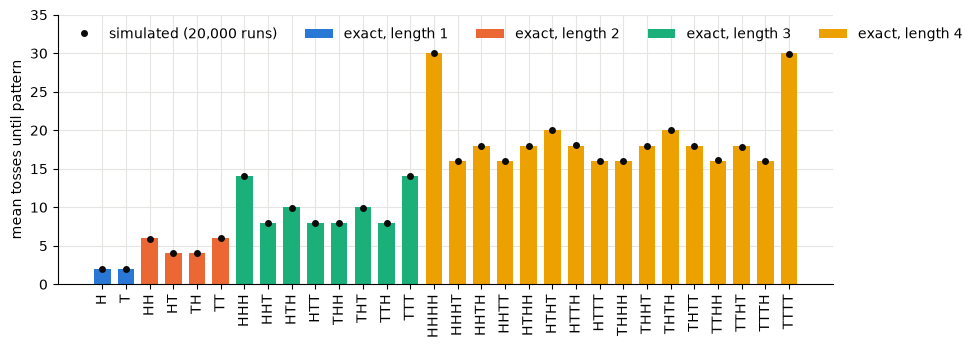

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(means.index, means["exact mean"], color=[COLORS[k - 1] for k in means["length"]], width=0.7)
ax.plot(means.index, means["simulated mean"], "o", color="#0b0b0b", ms=4, label="simulated (20,000 runs)")
for k in range(1, 5):
    ax.bar(0, 0, color=COLORS[k - 1], label=f"exact, length {k}")
ax.set_ylabel("mean tosses until pattern")
ax.tick_params(axis="x", rotation=90)
ax.legend(ncol=5, loc="upper left", frameon=False)
ax.set_ylim(0, 35)
plt.show()

Within each length the means range from 2^k for patterns that do not overlap themselves (`HT`, `TTTH`: 16)
up to 2^(k+1) - 2 for runs of one face (`HHHH`: 30). The simulation agrees to within sampling error.

## Distribution of waiting times for `TTTH`

A simulation of 20,000 runs next to the exact distribution,
P(N = n) = P(N > n-1) - P(N > n).

In [4]:
N_RUNS = 20_000
waits = patterns.simulate_waiting_times("TTTH", N_RUNS, rng=2008)
dist = pd.DataFrame({
    "simulated": patterns.waiting_time_counts(waits),
    "exact": patterns.waiting_time_pmf("TTTH", 120) * N_RUNS,
}).fillna(0)
print(f"mean: simulated {waits.mean():.2f}, exact {patterns.expected_tosses('TTTH')}")
dist.loc[4:20].round(1).T

mean: simulated 15.99, exact 16


tosses,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
simulated,1206.0,1164.0,1242.0,1240.0,1201.0,1073.0,1071.0,905.0,848.0,813.0,784.0,691.0,615.0,580.0,543.0,496.0,435.0
exact,1250.0,1250.0,1250.0,1250.0,1171.9,1093.8,1015.6,937.5,864.3,795.9,732.4,673.8,619.8,570.1,524.3,482.2,443.4


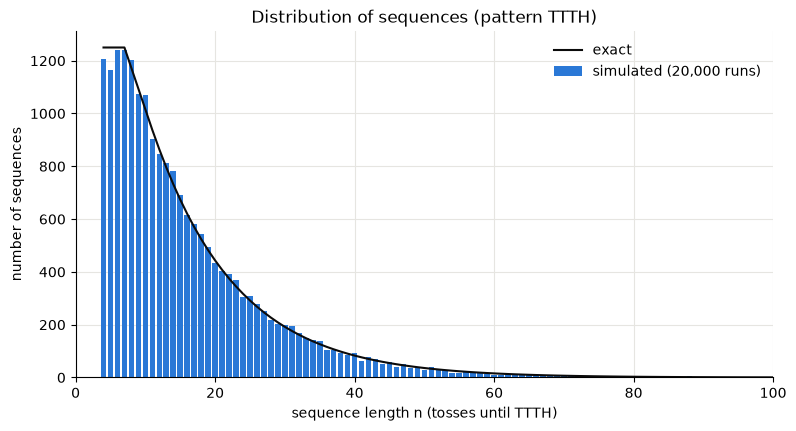

In [5]:
shown = dist.loc[4:100]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(shown.index, shown["simulated"], width=0.8, color=COLORS[0], label="simulated (20,000 runs)")
ax.plot(shown.index, shown["exact"], color="#0b0b0b", lw=1.5, label="exact")
ax.set_xlim(0, 100)
ax.set_xlabel("sequence length n (tosses until TTTH)")
ax.set_ylabel("number of sequences")
ax.set_title("Distribution of sequences (pattern TTTH)")
ax.legend(frameon=False)
plt.show()

The first four bars are flat at 1/16 of the runs. For n = 4..7 the n - 4 tosses before the final `TTTH`
are too short to contain it, and `TTTH` cannot overlap itself, so any start works. From n = 8 on, the start must
itself avoid `TTTH` and the tail decays geometrically.

## Sequences that avoid a pattern

Count the length-n sequences that never contain the pattern. `count_without_pattern` does this exactly with a
small state machine (state = how much of the pattern has just been seen); `sequences_without_pattern` generates
all 2^n sequences and filters them, for checking.
The fraction of sequences without the pattern is P(waiting time > n).

In [6]:
PATTERNS = ["TH", "HH", "THT", "THH"]
N_MAX = 21
counts = pd.DataFrame({p: [patterns.count_without_pattern(n, p) for n in range(1, N_MAX + 1)] for p in PATTERNS},
                      index=pd.RangeIndex(1, N_MAX + 1, name="tosses"))
counts["all"] = 2 ** counts.index
counts.T

tosses,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
TH,2,3,4,5,6,7,8,9,10,11,...,13,14,15,16,17,18,19,20,21,22
HH,2,3,5,8,13,21,34,55,89,144,...,377,610,987,1597,2584,4181,6765,10946,17711,28657
THT,2,4,7,12,21,37,65,114,200,351,...,1081,1897,3329,5842,10252,17991,31572,55405,97229,170625
THH,2,4,7,12,20,33,54,88,143,232,...,609,986,1596,2583,4180,6764,10945,17710,28656,46367
all,2,4,8,16,32,64,128,256,512,1024,...,4096,8192,16384,32768,65536,131072,262144,524288,1048576,2097152


- `TH`: n + 1. A sequence without `TH` is some heads followed by some tails.
- `HH`: the Fibonacci numbers. A sequence without `HH` ends in `T` (any shorter one, plus T) or in `TH`.
- `THT` and `THH` agree up to n = 4 and then separate: `THT` overlaps itself, so its occurrences cluster and
  more sequences miss it entirely.

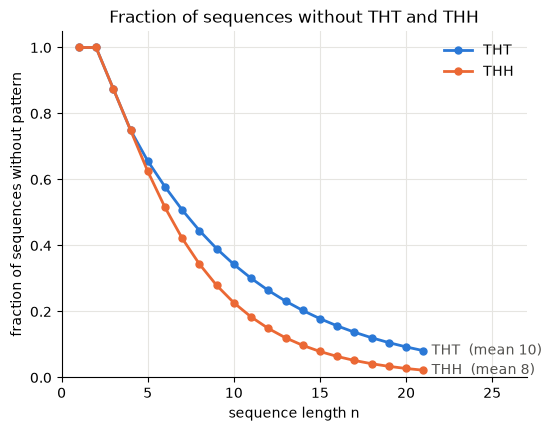

In [7]:
survival = patterns.survival_table(PATTERNS, N_MAX)

fig, ax = plt.subplots(figsize=(6, 4.5))
for p, color in zip(["THT", "THH"], COLORS):
    ax.plot(survival.index, survival[p], "-o", ms=5, lw=2, color=color, label=p)
    ax.annotate(f"{p}  (mean {patterns.expected_tosses(p)})", (N_MAX, survival[p].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color="#52514e")
ax.set_xlim(0, N_MAX + 6)
ax.set_ylim(0, 1.05)
ax.set_xlabel("sequence length n")
ax.set_ylabel("fraction of sequences without pattern")
ax.set_title("Fraction of sequences without THT and THH")
ax.legend(frameon=False)
plt.show()

The mean waiting time is the area under these curves, E[N] = sum over n >= 0 of P(N > n), which is 10 for
`THT` and 8 for `THH`.

In [8]:
long = patterns.survival_table(["THT", "THH"], 300)
(1 + long.sum()).round(6)

THT    10.0
THH     8.0
dtype: float64

## A long run of heads

Five heads in a row takes 2 + 4 + 8 + 16 + 32 = 62 tosses on average, with a long tail.

In [9]:
waits = patterns.simulate_waiting_times("HHHHH", 20_000, rng=5)
print(f"simulated mean {waits.mean():.1f}, exact {patterns.expected_tosses('HHHHH')}")
pd.Series(waits).describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1)

simulated mean 62.3, exact 62


count    20000.0
mean        62.3
std         58.7
min          5.0
10%         10.0
50%         44.0
90%        138.0
99%        273.0
max        540.0
dtype: float64